# NASA EPSCoR Progress: EOM Polarization Transfer (Jones/Mueller) Measurement
### 20261114 - *Tyndale Stutzman*
---

## Introduction:

This notebook measures how each EOM transforms polarization as a function of drive voltage, one EOM at a time, so
that a later analysis campaign can reconstruct each EOM's Mueller matrix $M(V)$ (and its Jones matrix, up to a global
phase) for the polarimeter simulation. The PAX polarimeter measures the input state at seat **A** (the EOM input
position), then is moved to seat **B** (after the EOM) to measure the output while the EOM is driven. One **block**
per input state; the block cells are run once per state and then run again from the top of the block for the next
state. Nothing is reconstructed here: the notebook saves raw PAX records, drive settings and operator notes.
The polarimeter calibration (black-box instrument matrix with the PD) is a separate campaign.

## Table of Contents

1. [Background](#background)
   1. [Measurement plan](#plan)
   1. [Decisions](#decisions)
1. [Setup](#setup)
   1. [Environment & Packages](#env)
   1. [Parameter Configuration](#conf)
   1. [Session Start](#session)
1. [Measurement Block](#block) (repeat per input state)
   1. [A1 Align the input at seat A](#a1)
   1. [A2 Log the state and capture the input](#a2)
   1. [B1 Undriven baseline at seat B](#b1)
   1. [B2 Sweep](#b2)
   1. [B3 Undriven baseline after the sweep](#b3)
   1. [A4 Return to seat A](#a4)
   1. [Verdict](#verdict)
1. [Blank Run (EOM out)](#blank)
1. [Close](#close)

<a id="background"></a>
## Background

<a id="plan"></a>
### Measurement plan

**Question:** For each EOM at 830 nm, what output polarization (full Stokes vector) does each of 4–6 known input
states give as a function of drive voltage, and how stable is that over a session?

**Prediction:** An ideal Pockels cell is a linear retarder, $\Gamma(V) = \Gamma_0 + \pi V/V_\pi$ about a fixed axis,
so for each input the output traces a circle on the Poincaré sphere (a great circle only for an input 90° away
from the axis on the sphere; inputs near the axis barely move). EO-PM-NR-C1: $V_\pi \approx 0.84$ V command, so the
sweep (≈ 1.1 $V_\pi$) covers ≈ 200° of arc. $\Gamma_0$ is unknown and temperature dependent (single crystal, TEC).

**Method:**

```mermaid
flowchart TD
    S["Session start<br/>config, HV check, ambient (beam blocked)"] --> A1
    A1["A1 align at seat A<br/>PyVista viewer, HV off"] --> A2["A2 type state, PSG dials, TEC<br/>30 s PAX: input_A"]
    A2 --> B1["B1 PAX to seat B, HV off<br/>30 s undriven: baseline_B"]
    B1 --> B2["B2 HV on, sine sweep, ~20 cycles<br/>sweep_B"]
    B2 --> B3["B3 HV off<br/>30 s undriven: baseline_B_post"]
    B3 --> A4["A4 PAX to seat A<br/>30 s: return_A"]
    A4 --> V{"Verdict"}
    V -- "next state, or redo" --> A1
    V -- "all states done" --> X["Blank run (EOM out), then close"]
```

**Derivation:** With Stokes vectors $S = (S_0, S_1, S_2, S_3)$, the EOM acts as
$$S_\text{out}(V) = M(V)\,S_\text{in}.$$
One block gives $M(V)\,S_\text{in}$ for one input: four numbers per voltage, not matrix elements. Stacking
$n \ge 4$ blocks whose inputs are linearly independent (one must be circular, since H, V, D, A have no $S_3$),
$$\big[S_\text{out}^{(1)} \cdots S_\text{out}^{(n)}\big] = M(V)\,\big[S_\text{in}^{(1)} \cdots S_\text{in}^{(n)}\big],$$
which the analysis campaign solves. The PAX reports azimuth $\theta$, ellipticity $\eta$, DoP and power, so
$S = P\,[1,\ \text{DoP}\cos2\eta\cos2\theta,\ \text{DoP}\cos2\eta\sin2\theta,\ \text{DoP}\sin2\eta]$.

*Undriven captures.* `baseline_B` gives $M(0)\,S_\text{in}$ (static birefringence) and the transmission
$P_B/P_A$ for that input. `baseline_B_post` vs `baseline_B` shows EOM drift within the block; `return_A` vs `input_A`
shows laser-power and PSG drift.

*Timing.* The drive is $V(t) = c + a\sin\!\big(2\pi f (t - t_0)\big)$ with $f$ read back from the RP. A PAX record
stamped $t$ describes roughly $V(t - \tau)$, with $\tau$ the PAX lag (≈ 130 ms, operator estimate). An error in $t_0$
looks exactly like a lag. Both are left to the analysis. The first sweep of each session runs at two periods
(8.59 s and 4.29 s, whole RP frequency steps) so the analysis can compare them: a gap between the rising and falling halves that grows with speed is
lag; a gap that stays the same is hysteresis. The raw look's command axis has only an approximate phase, so it
cannot make that call; a tee of the drive helps the analysis, with a host-time precision not yet characterized.

*Speed bound.* The PAX assumes a constant state during one waveplate revolution (≈ 17 ms at 60 Hz). With a ≈ 10 s
period, the retardance changes by ≲ 2° per revolution; keep the period ≥ 3 s.

**What could fool us** (ranked):
1. **$\Gamma_0$ drift** of the single crystal (temperature) between blocks: the reconstruction assumes one $M(V)$
   for all blocks. Watch `baseline_B` vs `baseline_B_post`; optionally repeat the first state as the last block.
2. **Phase origin vs lag vs hysteresis.** $t_0$ is known only to the timing window of the RP call. A tee of the drive
   onto a free RP input anchors each segment's phase (buffer right after each frequency change).
3. **PAX seat roll between A and B** rotates every output about $S_3$ and can hide a handedness flip: the blank run
   (EOM out, ≥ 4 states incl. circular) measures the A→B transform.
4. **Laser power drift** enters $P_B/P_A$: bracketed by `input_A` and `return_A` only.
5. **PAX smearing** if the state changes within a revolution: DoP dips at the fast parts of the sine.
6. **Delivered volts ≠ command:** 302 gain and zero from 2026-11-05 (before the 11-06 bias re-set); OUT2 never
   characterized; the HV at the EOM is not measured.
7. **Viewer vs capture mode:** the viewer runs the upstream daemon (measurement mode 9), captures use the project
   daemon (mode 5).
8. **Driver steps:** `set_waveform` jumps the output to the sine offset and the session exit steps it to zero (as in
   the 2026-11-06 runs).

**Observed, 2026-11-14/16 (4004):** DoP at B ≈ 0.68–0.72 for inputs off the EOM axis (H, circular), ≈ 1.01 for
the A input near the axis; input DoP ≈ 1.00–1.02 (four PBS before the PSG). Operator and professor: not a concern
for now. The 0 V retardance drifts a few degrees per block (`baseline_B` vs `baseline_B_post`).

**Rerunning a cell by accident is harmless:** a stage cell whose file exists prints a note and does nothing.

**Redo rule:** redo a block (new block, note says which it replaces) only for an operational fault: optic bumped,
PAX seat not clicked in, PAX error or interruption, HV not on or tripped, gross mislabel (set R, measured near L),
laser power jump between `input_A` and `return_A`. **Never** because the data look unexpected, the DoP is low or
the circle is not round. Rejected blocks stay on disk.

<a id="decisions"></a>
### Decisions

| # | Decision | Why | Approved |
| --- | --- | --- | --- |
| 1 | 30 s PAX capture for every undriven measurement (A and B) | precise input, range of outputs | TS 2026-11-14 (design) |
| 2 | Display mean = mean of full Stokes over accepted reads, with spread; raw always kept | Stokes vectors add; angles wrap | |
| 3 | Sine, span ≈ 1.1 $V_\pi$ inside the command window | covers $V_\pi$ retardance with margin | TS 2026-11-14 (span) |
| 3a | Period 8.59 s (one RP frequency step, 0.1164 Hz) × 20 cycles; first sweep of a session adds 4.29 s × 20 | speed bound; lag vs hysteresis; RP cannot make 0.1 Hz | |
| 4 | Return to A for 30 s after each sweep | laser / PSG drift | TS 2026-11-14 |
| 5 | Redo rule above (operational faults only) | avoid selecting data by appearance | |
| 6 | No lag correction, cycle exclusion or averaging stored by this notebook | the analysis campaign decides | |

<a id="setup"></a>
## Setup

<a id="env"></a>
### Environment & Packages

Run this notebook in `jl-env`, from `notebooks/`. The plumbing lives in `python/eom_jones/` (tested with fakes:
`python/eom_jones/tests/`).

In [95]:
import sys
from pathlib import Path
from importlib.metadata import version

src = (Path("python") if Path("python").is_dir() else Path("../python")).resolve()
assert (src / "eom_jones").is_dir(), "Start in the repo root or notebooks/"
for directory in (src, src.parent):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

print(f"Python {sys.version.split()[0]} | {sys.executable}")
print({name: version(name) for name in ("numpy", "matplotlib", "pyrpl", "yaqc", "yaqd-thorlabs")})

Python 3.10.20 | /home/augustus/miniconda3/envs/jl-env/bin/python3.10
{'numpy': '2.2.5', 'matplotlib': '3.10.9', 'pyrpl': '0.9.8.0', 'yaqc': '2023.6.0', 'yaqd-thorlabs': '2025.12.0'}


<a id="conf"></a>
### Parameter Configuration

Typed by hand: which EOM is in the beam, the bench log and the sweep. Each EOM's facts are in `eoms` with their
source. **Only one EOM in the beam.** The path is straight; only the EOM sits between seats A and B.
Safe state: **HV driver off, or on with the RP at 0 V command** (operator 2026-11-16, recorded as `hv_safe_state`;
the RP is at zero/off outside the sweep cell). The 4004 session used driver-off baselines; from the Thorlabs session on,
undriven baselines are at 0 V command, i.e. the driver's zero (≈ +1.3 V for the 302), and `baseline_B_post` can
catch the 302's recovery tail after the sweep.

- EO-PM-NR-C1: RP **OUT1** → BNC tee (→ IN1, LV) → Conoptics 302 → push-pull adapter → EOM (operator 2026-11-16, afternoon;
  302 bias unchanged since its last use). OUT2 still goes to the preamp → 3211 (4004 chain).
- Newport 4004: RP **OUT2** → BNC tee (→ IN2, LV) → preamp → New Focus 3211 → EOM (operator 2026-11-16).
  The 2026-11-14 session drove OUT1 (then cabled to the 302, not the 3211): its sweeps did not drive the 4004.

The HV check below uses the driver's output at 0 V command (`hv_zero_v`): type the last reading and how/when it was
taken, for the driver of the EOM under test. Both gains were measured on OUT1 (the 4004 chain on 2026-10-28,
the 302 on 2026-11-05); on OUT2 they may differ by a few %.

In [96]:
import math

# Connections (as in the EOM characterization notebook).
rp_hostname = "192.168.1.98"
rp_config = "scope_config"
ssh_host_key_sha256 = "W5g8Qcvu7r+8mMQZInHzNLpvOpYsvnCvo5hwYkWJCRY"
pax_daemon_config_path = src / "polarization_locking/hardware/pax1000.toml"   # project daemon, mode 5
pax_measurement_wait_s = 0.06
viewer_script = src / "PAX1000/PAX1000-PS_live_plot-PyVista.py"               # upstream daemon, mode 9
viewer_python = Path("/home/augustus/miniconda3/envs/jl-env/bin/python")
results_directory = src.parent / "experiments" / "_local"
wavelength_nm = 830.0

eoms = {
    "EO-PM-NR-C1": dict(
        output="out1", driver="Conoptics 302, RP direct",   # operator 2026-11-16 pm: OUT1 -> tee (IN1) -> 302
        hv_per_command_v=350.1,       # two-point DMM, EOM disconnected, measured on OUT1 (2026-11-05, Decision 15)
        hv_limit_v=420.0,             # operator 2026-11-06
        command_min_v=-0.055,         # 302 pins at -19.3 V below about -0.059 V command (2026-11-05)
        command_max_v=1.0,            # RP maximum
        vpi_command_v=0.84),          # retardance, Senarmont, 1 Hz sine on OUT1 (2026-11-06)
    "Newport 4004": dict(
        output="out2", driver="preamp -> New Focus 3211",   # operator 2026-11-16; gain/Vpi below measured on OUT1
        hv_per_command_v=406.0,       # one DMM point at +0.30 V (2026-10-28)
        hv_limit_v=200.0,             # 3211 +/-200 V
        command_min_v=-0.48, command_max_v=0.48,   # about 195 V (2026-10-28 SUMMARY)
        vpi_command_v=0.514),         # 2026-10-28
}
eom_under_test = "EO-PM-NR-C1"         # TYPE: the EOM in the beam now
eom = eoms[eom_under_test]

# Bench log: fill every None before the session starts.
bench = {
    "eom_serial": "",               # from the EOM label
    "hv_zero_v": 0.059,                # driver output at 0 V command (V), number
    "hv_zero_source": "302: reading typed 2026-11-13 (biased to zero, DMM, EOM disconnected); 302 bias unchanged since (operator 2026-11-16)",         # how and when it was read (e.g. "DMM, EOM disconnected, 2026-11-05")
    "tec_setpoint": "11.70 (rests at 11.63, operator 2026-11-16)",
    "psg_optics": "PBS, HWP, QWP",               # which elements make the PSG (e.g. "polarizer, HWP, QWP")
    "pax_seats": "mag base",                # how A and B are mounted (repeatable mount)
    "tee": "OUT1 tee -> IN1 (LV)",                      # "OUT2 tee -> IN2 (LV)" or "none"
    "hv_safe_state": "302 stays on; RP at 0 V command counts as safe for this notebook (operator 2026-11-16; avoids driver switching transients)",
    "notes": "Thorlabs EOM installed and aligned 2026-11-16: PAX ~650 uW before the EOM, best ~635 uW through it (operator)",
    "rp_loopback_check": ("2026-11-16, agent run authorized by operator, drivers off, DC +/-0.1 V, means of one "
                          "8 ms buffer: OUT1->IN1 +0.0921/-0.1024 V (zero -0.0054), OUT2->IN2 +0.1023/-0.1013 V "
                          "(zero +0.0001); crosstalk < 0.3 mV both ways; cleanup COMPLETED"),
}
tee_input = "in1"                     # "in1" or "in2" if the driven output is teed onto an RP input, else None
rp_jumpers = {"in1": "LV", "in2": "LV"}

# Sweep (Decision 3): span = 1.1 Vpi command, centred in the window, clipped to it.
lo, hi = eom["command_min_v"], eom["command_max_v"]
sweep_offset_v = round((lo + hi) / 2, 4)
sweep_peak_v = round(min(1.1 * eom["vpi_command_v"] / 2, (hi - lo) / 2), 4)
# The RP sine frequency comes in steps of 125 MHz / 2**30 = 0.1164 Hz (2026-11-14 readback): request whole steps
# so the requested period is the actual one. 1 step = 8.59 s, 2 steps = 4.29 s (Decision 3a).
asg_step_hz = 125e6 / 2**30
segments_first = [{"period_s": 1 / asg_step_hz, "cycles": 20}, {"period_s": 1 / (2 * asg_step_hz), "cycles": 20}]
segments_later = [{"period_s": 1 / asg_step_hz, "cycles": 20}]
capture_s = 30.0                      # Decision 1

missing = [k for k, v in bench.items() if v is None]
assert not missing, f"Fill the bench log first: {missing}"
zero, gain = float(bench["hv_zero_v"]), eom["hv_per_command_v"]
hv_extremes = (zero + gain * (sweep_offset_v - sweep_peak_v), zero + gain * (sweep_offset_v + sweep_peak_v))
hv_window = (zero + gain * lo, zero + gain * hi)
assert max(abs(v) for v in hv_window) <= eom["hv_limit_v"], f"Command window reaches {hv_window} V"
print(f"{eom_under_test} on {eom['output'].upper()} via {eom['driver']}")
print(f"Sweep {sweep_offset_v:+.4f} ± {sweep_peak_v:.4f} V command = {2 * sweep_peak_v / eom['vpi_command_v']:.2f} Vπ"
      f" ≈ {hv_extremes[0]:+.0f} … {hv_extremes[1]:+.0f} V at the driver (limit ±{eom['hv_limit_v']:.0f} V;"
      f" gain from OUT1, a few % uncertain on another output)")

EO-PM-NR-C1 on OUT1 via Conoptics 302, RP direct
Sweep +0.4725 ± 0.4620 V command = 1.10 Vπ ≈ +4 … +327 V at the driver (limit ±420 V; gain from OUT1, a few % uncertain on another output)


<a id="session"></a>
### Session Start

Creates the session folder in `experiments/_local/` (rerunning the cell reuses it unless the EOM or the bench log
changed; `resume_session` continues an earlier folder) and records settings, git state and the text of the viewer
script, PAX config and plumbing. Then an ambient reading with the beam blocked (PAX at A, `read_raw`, may repeat
records).

In [97]:
from importlib import reload
import json
import numpy as np
import eom_jones.acquire as aq
import eom_jones.plots as plots
import instruments.pax as pax_interface
import instruments.red_pitaya as rp_interface

aq, plots = reload(aq), reload(plots)
PAX, RedPitaya = reload(pax_interface).PAX, reload(rp_interface).RedPitaya

pax_factory = lambda: PAX.local_session(config_path=pax_daemon_config_path, measurement_wait_s=pax_measurement_wait_s)
drive_factory = lambda: RedPitaya.drive_session(
    rp_hostname, profile=rp_config, ssh_host_key_sha256=ssh_host_key_sha256,
    command_limits_v={eom["output"]: [lo, hi]}, frequency_limits_hz=[0.01, 0.34],   # period >= 3 s
    max_peak_v=(hi - lo) / 2, frequency_correction=1.0)
tee = None if tee_input is None else {"decimation": 65536, "input": tee_input,      # 8.6 s buffer
                                      "full_scale_v": {k: {"LV": 1.0, "HV": 20.0}[v] for k, v in rp_jumpers.items()}}

settings = dict(eom_under_test=eom_under_test, eom=eom, bench=bench, wavelength_nm=wavelength_nm,
                sweep={"offset_v": sweep_offset_v, "peak_v": sweep_peak_v, "segments_first": segments_first,
                       "segments_later": segments_later, "hv_extremes_v": hv_extremes},
                capture_s=capture_s, tee=tee, rp_jumpers=rp_jumpers, python=sys.version,
                packages={n: version(n) for n in ("numpy", "matplotlib", "pyrpl", "yaqc", "yaqd-thorlabs")},
                viewer_measurement_mode="9 (upstream daemon hard-codes SENS:CALC 9); captures: project daemon, mode 5",
                provenance=aq.provenance(src.parent, [
                    viewer_script, viewer_script.with_name("pax1000.toml"), pax_daemon_config_path,
                    src / "eom_jones/acquire.py", src / "eom_jones/plots.py", src / "instruments/_rp_drive.py",
                    src / "instruments/pax.py", src / "instruments/_pax_session.py"]))
resume_session = None   # or the path of an earlier session folder to keep adding blocks to it (e.g. after a restart)
if resume_session:
    session = Path(resume_session)
elif globals().get("session_key") != (eom_under_test, json.dumps(bench, sort_keys=True)):
    session = aq.new_session(results_directory, eom_under_test, settings)   # new EOM or changed bench log only
    session_key = (eom_under_test, json.dumps(bench, sort_keys=True))
print(f"session: {session}")

session: /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/jones_EO-PM-NR-C1_20261116T201300Z


In [98]:
# Every PAX step (viewer, captures, sweep) first stops any other PAX daemon, logged in pax_cleanup.log.
# Run this cell to do it by hand.
aq.clear_pax(session, "manual")
print(f"PAX port 38400 free: {not aq.port_in_use(38400)}")

PAX port 38400 free: True


In [99]:
# Ambient: block the beam, PAX at seat A, HV off.
assert input("Beam blocked and PAX at seat A? [y/N] ") == "y", "Stopped: nothing measured"
aq.ambient(session, pax_factory=pax_factory, duration_s=10.0, wavelength_nm=wavelength_nm)
amb, _ = aq.load_stage(session, "ambient")
print(f"ambient ptotal {np.nanmedian(amb['ptotal']) * 1e6:.3f} µW median of {len(amb['ptotal'])} raw records "
      f"(range {np.nanmin(amb['ptotal']) * 1e6:.3f} … {np.nanmax(amb['ptotal']) * 1e6:.3f}). Unblock the beam.")

Beam blocked and PAX at seat A? [y/N]  y


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
ambient ptotal 0.002 µW median of 70 raw records (range 0.002 … 0.002). Unblock the beam.


<a id="block"></a>
## Measurement Block

Run **A1 → Verdict** once per input state (H, V, D, R at least; A, L optional), then come back to A1.
Each stage writes its own file and refuses to run twice or out of order; to redo, start a new block at A2.
A stage that fails before taking any reading (PAX did not start, HV prompt declined) leaves no file, only a line in
`failed_starts.log`: just rerun the cell. A stage that took some readings keeps them (status failed/interrupted):
finish the block (B3, A4, verdict "redo") and start a new one. Rerunning A2 before any capture reuses that block.
**Every "HV OFF" confirmation is mandatory**, also after a failed or interrupted sweep.

<a id="a1"></a>
### A1 Align the input at seat A

PAX at seat A, HV off. The viewer opens in its own window (it starts its own PAX daemon, set to 830 nm). Any other PAX daemon is stopped
first, and the viewer's daemon is stopped after the window closes even if the viewer crashes.
Set the PSG by eye to the wanted point on the sphere, then **close the window**. The cell waits until it is closed.

In [145]:
viewer = aq.launch_viewer(session, viewer_script, viewer_python)
print(f"viewer closed (return code {viewer['returncode']}); leftover daemons stopped: {len(viewer['daemons_left_running'])}")
if viewer["returncode"] != 0:
    print("Viewer exited with an error; see", sorted(session.glob("viewer_*.log"))[-1].name)

viewer closed (return code 0); leftover daemons stopped: 0


<a id="a2"></a>
### A2 Log the state and capture the input

Run, then answer the prompts one at a time (state, PSG dials, TEC, note): a new block and a 30 s capture at seat A (`input_A`). The mean printed below is a display
(Decision 2); the raw records are what is saved.

In [146]:
# Typed one at a time; an empty answer stops the cell before anything is created.
state_label = input("State set at A (H, V, D, A, R, L): ").strip()
assert state_label, "Type the state"
psg_dials = input("PSG dials as read now (e.g. HWP 144, QWP 264): ").strip()
assert psg_dials, "Type the PSG dials"
tec_read = input("TEC thermistor reading now: ").strip()
assert tec_read, "Type the TEC reading"
note = input("Note (Enter to skip): ").strip()
block = aq.new_block(session, state_label, {"psg_dials": psg_dials, "tec_read": tec_read, "note": note})
aq.capture(block, "input_A", pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
print(block)

State set at A (H, V, D, A, R, L):  D
PSG dials as read now (e.g. HWP 144, QWP 264):  HWP 165, QWP 040
TEC thermistor reading now:  11.63
Note (Enter to skip):  final reading before EOM out


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
/home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/jones_EO-PM-NR-C1_20261116T201300Z/blocks/06_D


[display, Decision 2 pending] 06_D/input_A: 208 reads | P = 637.89 ± 0.47 µW | S/S0 = [-0.0026, +0.9937, +0.0010] ± [0.0001, 0.0007, 0.0000] | DoP of mean 0.9937, mean DoP 0.9937


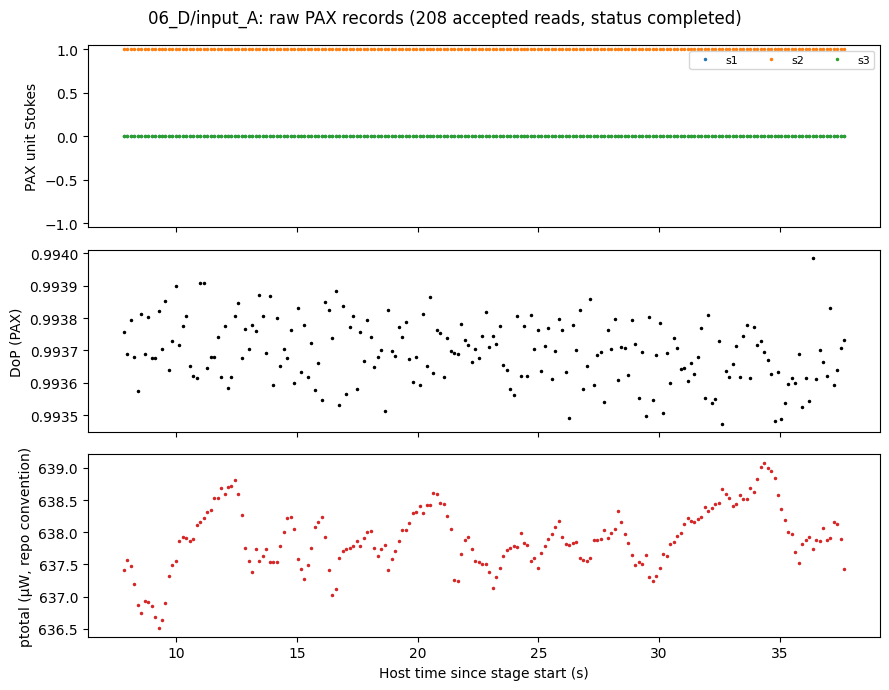

In [147]:
# Display only (Decision 2, pending): mean of full Stokes over the accepted reads, S = P·[1, DoP·s1, DoP·s2, DoP·s3].
def stokes_summary(block, stage):
    a, _ = aq.load_stage(block, stage)
    s1, s2, s3 = plots.unit_stokes(a)
    S = a["ptotal"][:, None] * np.column_stack([np.ones_like(s1), a["dop"] * s1, a["dop"] * s2, a["dop"] * s3])
    mean, spread = S.mean(axis=0), S.std(axis=0)
    print(f"[display, Decision 2 pending] {block.name}/{stage}: {len(S)} reads | P = {mean[0] * 1e6:.2f} ± {spread[0] * 1e6:.2f} µW | "
          f"S/S0 = [{', '.join(f'{m:+.4f}' for m in mean[1:] / mean[0])}] ± "
          f"[{', '.join(f'{d:.4f}' for d in spread[1:] / mean[0])}] | "
          f"DoP of mean {np.linalg.norm(mean[1:]) / mean[0]:.4f}, mean DoP {a['dop'].mean():.4f}")

stokes_summary(block, "input_A")
plots.raw_look_capture(block, "input_A")

<a id="b1"></a>
### B1 Undriven baseline at seat B

HV off. Move the PAX to seat B. 30 s undriven capture: $M(0)\,S_\text{in}$ and transmission for this input.

PAX seated at B and HV safe (driver off, or on with RP at 0 V command)? [y/N]  y


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
[display, Decision 2 pending] 06_D/baseline_B: 208 reads | P = 632.61 ± 0.31 µW | S/S0 = [+0.0008, +0.6701, -0.7096] ± [0.0001, 0.0003, 0.0004] | DoP of mean 0.9760, mean DoP 0.9760


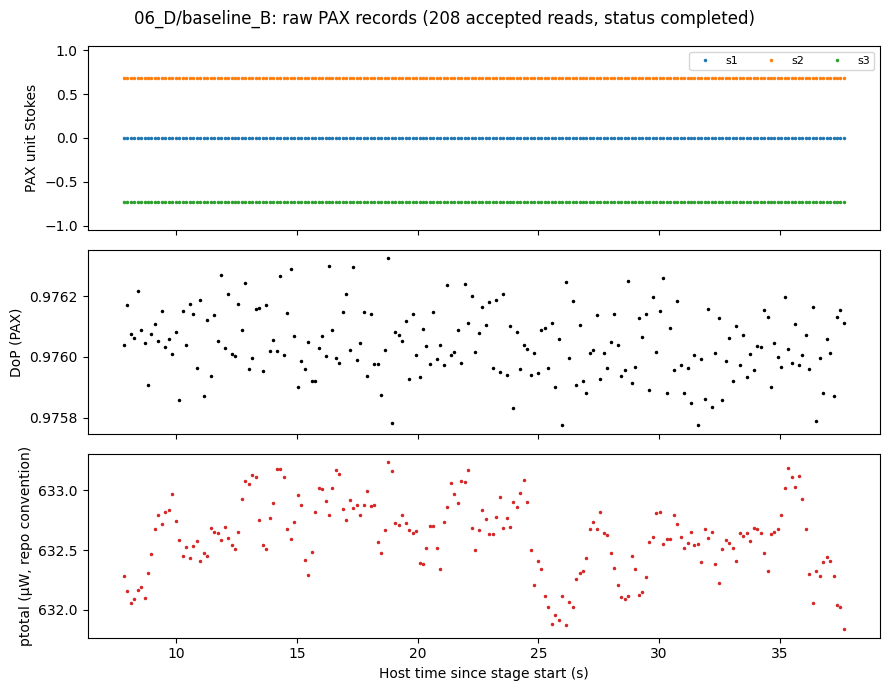

In [148]:
stage = "baseline_B"
if aq.stage_done(block, stage):
    print(f"{block.name}: {stage} already recorded; go on to the next cell")
else:
    assert input("PAX seated at B and HV safe (driver off, or on with RP at 0 V command)? [y/N] ") == "y", "Stopped: nothing measured"
    aq.capture(block, stage, pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
    stokes_summary(block, stage)
    plots.raw_look_capture(block, stage)

<a id="b2"></a>
### B2 Sweep

The cell starts the PAX, connects the RP (outputs confirmed zero/off), then asks you to **switch the HV driver on**.
The sine runs for 20 cycles (the first sweep of the session also runs 20 cycles at half the period), then the RP
returns to zero/off. Do not switch the HV off until the cell has finished.

In [149]:
stage = "sweep_B"
first = not any(r["stages"].get(stage) == "completed" for r in aq.ledger(session))
segments = segments_first if first else segments_later
if aq.stage_done(block, stage):
    print(f"{block.name}: {stage} already recorded; go on to the next cell")
else:
    print(f"segments: {segments} (≈ {sum(s['period_s'] * s['cycles'] for s in segments) / 60:.1f} min of drive)")
    hv_on = lambda: input("RP connected at zero. HV driver ON (switch it on now if it is off)? [y/N] ") == "y"
    try:
        aq.sweep(block, pax_factory=pax_factory, drive_factory=drive_factory, confirm_hv_on=hv_on, output=eom["output"],
                 offset_v=sweep_offset_v, peak_v=sweep_peak_v, segments=segments, tee=tee, wavelength_nm=wavelength_nm)
    except BaseException:
        print("Sweep stopped. RP outputs were returned to zero/off. SWITCH THE HV DRIVER OFF, then continue at B3.")
        raise

segments: [{'period_s': 8.589934592, 'cycles': 20}] (≈ 2.9 min of drive)
Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).


INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


RP connected at zero. HV driver ON (switch it on now if it is off)? [y/N]  y


PAX daemon exited; motor-stop command and USB close succeeded.


<a id="b3"></a>
### B3 Undriven baseline after the sweep

Switch the HV driver **off** (also if the sweep failed). 30 s undriven capture at B: drift of the EOM within the block.
Then the raw look of the sweep.

In [150]:
stage = "baseline_B_post"
if aq.stage_done(block, stage):
    print(f"{block.name}: {stage} already recorded; go on to the next cell")
else:
    assert input("Sweep over, RP back at 0 V command (driver may stay on)? [y/N] ") == "y", "Switch the HV driver off before continuing"
    aq.capture(block, stage, pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
    stokes_summary(block, stage)

Sweep over, RP back at 0 V command (driver may stay on)? [y/N]  y


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
[display, Decision 2 pending] 06_D/baseline_B_post: 208 reads | P = 632.02 ± 0.39 µW | S/S0 = [+0.0015, +0.5959, -0.7682] ± [0.0002, 0.0072, 0.0052] | DoP of mean 0.9722, mean DoP 0.9722


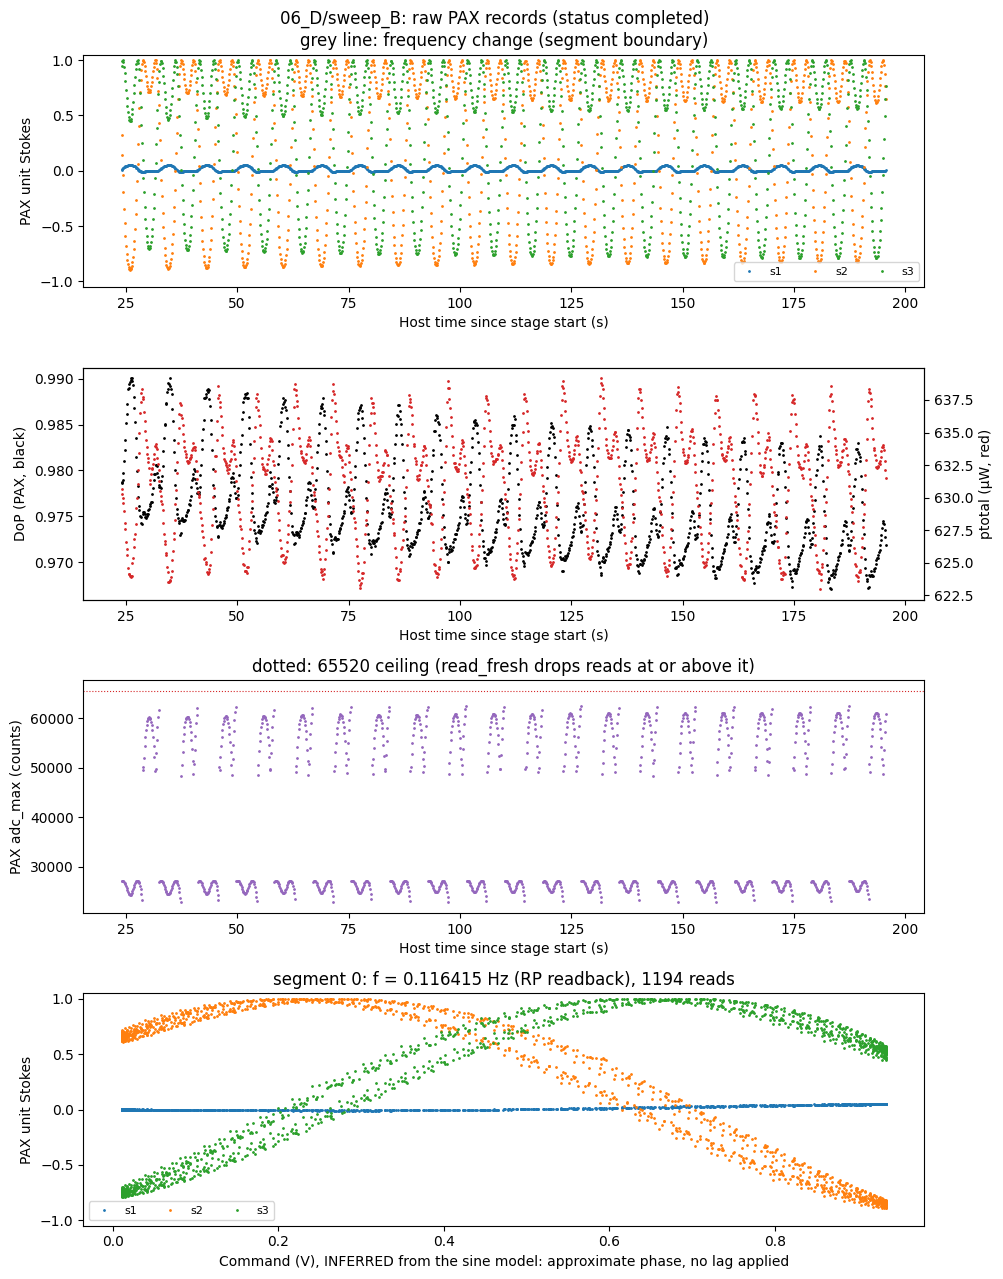

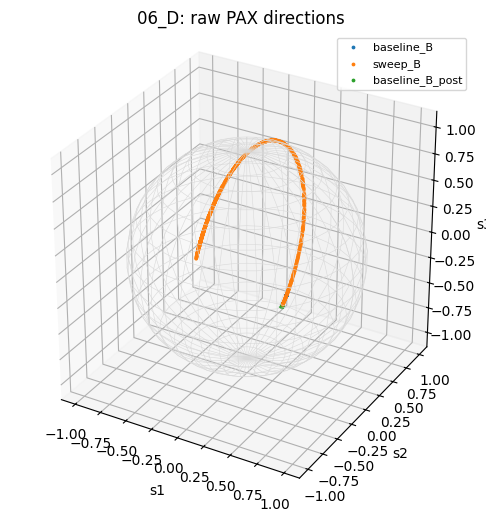

In [151]:
plots.raw_look_sweep(block)
plots.sphere(block, ["baseline_B", "sweep_B", "baseline_B_post"])   # on demand

<a id="a4"></a>
### A4 Return to seat A

HV off. Move the PAX back to seat A without touching the PSG. 30 s capture: laser-power and PSG drift over the block.

In [152]:
stage = "return_A"
if aq.stage_done(block, stage):
    print(f"{block.name}: {stage} already recorded; go on to the next cell")
else:
    assert input("HV safe (off, or RP at 0 V) and PAX back at seat A (PSG untouched)? [y/N] ") == "y", "Stopped: nothing measured"
    aq.capture(block, stage, pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
    stokes_summary(block, "input_A")
    stokes_summary(block, stage)

HV safe (off, or RP at 0 V) and PAX back at seat A (PSG untouched)? [y/N]  y


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
[display, Decision 2 pending] 06_D/input_A: 208 reads | P = 637.89 ± 0.47 µW | S/S0 = [-0.0026, +0.9937, +0.0010] ± [0.0001, 0.0007, 0.0000] | DoP of mean 0.9937, mean DoP 0.9937
[display, Decision 2 pending] 06_D/return_A: 208 reads | P = 646.83 ± 0.37 µW | S/S0 = [+0.0048, +0.9936, +0.0013] ± [0.0001, 0.0006, 0.0000] | DoP of mean 0.9936, mean DoP 0.9936


<a id="verdict"></a>
### Verdict

`"accept"` or `"redo"` (redo rule above; say what went wrong). Then go back to [A1](#a1) for the next state.

In [153]:
if aq.stage_done(block, "verdict"):
    print(f"{block.name}: verdict already recorded; next state: back to A1")
else:
    decision = input("Verdict, 'accept' or 'redo': ").strip()
    note = input("Note (what happened; required for redo): ").strip()
    assert decision == "accept" or note, "Say why it is a redo"
    aq.verdict(block, decision, note=note)
for row in aq.ledger(session):
    print(row)

Verdict, 'accept' or 'redo':  accept
Note (what happened; required for redo):  might be some suspicious drift. working that out rn before removing EOM


{'block': '01_D', 'label': 'D', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '02_L', 'label': 'L', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '03_V', 'label': 'V', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '04_H', 'label': 'H', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '05_A', 'label': 'A', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 

<a id="blank"></a>
## Blank Run (EOM out)

Take the EOM out of the beam, leave both seats as they are. For at least 4 states including a circular one: run
[A1](#a1) to align, then the cell below (`input_A` at A, then `baseline_B` at B). The analysis uses these pairs for
the A→B transform (seat roll, handedness). Put the EOM back afterwards; the next EOM session starts from the top.

In [154]:
state_label = input("Blank run, state set at A: ").strip()
assert state_label, "Type the state"
psg_dials = input("PSG dials as read now: ").strip()
assert psg_dials, "Type the PSG dials"
blank = aq.new_block(session, state_label, {"psg_dials": psg_dials, "tec_read": "n/a (EOM out)", "note": "blank run"},
                     kind="blank")
aq.capture(blank, "input_A", pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
stokes_summary(blank, "input_A")
assert input("EOM out, PAX seated at B? [y/N] ") == "y", "Stopped"
aq.capture(blank, "baseline_B", pax_factory=pax_factory, duration_s=capture_s, wavelength_nm=wavelength_nm)
stokes_summary(blank, "baseline_B")
aq.verdict(blank, "accept", note=input("Note (Enter to skip): ").strip())

Blank run, state set at A:  y
PSG dials as read now:  HWP 165, QWP 039


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
[display, Decision 2 pending] 07_y/input_A: 208 reads | P = 628.08 ± 0.36 µW | S/S0 = [-0.0001, +0.9933, +0.0009] ± [0.0002, 0.0006, 0.0000] | DoP of mean 0.9933, mean DoP 0.9933


EOM out, PAX seated at B? [y/N]  y


Starting local PAX daemon (includes 5 s motor settling)...
PAX session ready at 127.0.0.1:38400 (serial M01303584).
PAX daemon exited; motor-stop command and USB close succeeded.
[display, Decision 2 pending] 07_y/baseline_B: 208 reads | P = 632.69 ± 0.40 µW | S/S0 = [-0.0067, +0.9994, +0.0025] ± [0.0001, 0.0006, 0.0000] | DoP of mean 0.9994, mean DoP 0.9994


Note (Enter to skip):  hopefully final run step before analysis. fingers crossed. 


<a id="close"></a>
## Close

Confirm the HV driver is off. The session folder holds everything for the analysis campaign; nothing here is
reconstructed. Move the folder into the day folder at close-out (archivist).

In [155]:
for row in aq.ledger(session):
    print(row)
print(f"\nSession folder: {session}\nHV driver OFF? PAX daemon: none left running "
      f"(port 38400 in use: {aq.port_in_use(38400)})")

{'block': '01_D', 'label': 'D', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '02_L', 'label': 'L', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '03_V', 'label': 'V', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '04_H', 'label': 'H', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 'completed', 'return_A': 'completed'}, 'verdict': 'accept'}
{'block': '05_A', 'label': 'A', 'kind': 'eom', 'stages': {'input_A': 'completed', 'baseline_B': 'completed', 'sweep_B': 'completed', 'baseline_B_post': 